In [1]:
from pathlib import Path
import re
import json 
import sys
import os
import copy 

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib notebook
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

module_path = os.path.abspath(os.path.join('../'))
if module_path not in sys.path:
    sys.path.append(module_path)


In [245]:
results_gail = pkl.load(open('250923_gail.pkl','rb'))
results_airl = pkl.load(open('250923_airl_results.pkl','rb'))
results_airl_new = pkl.load(open('280124_airl_results.pkl','rb'))

#results_airl = pkl.load(open('280124_airl_results.pkl','rb'))
results_pwil = pkl.load(open('250923_pwil_results.pkl', 'rb'))
results_swil_old = pkl.load(open('220923_swil_results.pkl','rb'))
results_swil_new = pkl.load(open('170124_swil_results.pkl','rb'))
results_swil_2701 = pkl.load(open('280124_swil_results.pkl','rb'))
results_swil_2709 = pkl.load(open('270923_swil_results.pkl','rb'))


In [218]:
results_swil_2901_qlen20 = pkl.load(open('290123_swil_qlen20tanh_results.pkl','rb'))


KeyError: 1

In [223]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

d_swil_2901, d_swil_2901_mustd = process_results(envs, results_swil_2901_qlen20, ['use_next_obs', 'use_actions', 'swil_period'], ['True', 'True', '100.0'])


Incomplete length: swil Walker2d-v3 894 10 1 88


In [170]:
tags = ["charts/episodic_return", "eval/mu"]

In [250]:
def process_results(envs, results, param_filter_key_list, param_filter_value_list, n_demos=[1,4,10], sss=[1,20,100], seeds=[515, 234, 894, 322, 72], print_files=False):
    # filter into airl, gail_lip
    d, d_mustd = {}, {}
    
    #envs = ['AdroitHandDoor-v1', 'AdroitHandPen-v1', 'FrankaKitchen-v1']

    for env_name in envs:
        d[env_name] = {}
        for seed in seeds:
            d[env_name][seed] = {}
            for n_demo in n_demos:
                d[env_name][seed][n_demo]  = {}
                for ss in sss:
                    d[env_name][seed][n_demo][ss]  = {}
                    
    
    for env_name in envs:
        d_mustd[env_name] = {}
        for n_demo in n_demos:
            d_mustd[env_name][n_demo]  = {}
            for ss in sss:
                d_mustd[env_name][n_demo][ss]  = {}
                
    # load results and filter them according to keyss
    for k, v in results.items():
        hparams = v[2]
        env_name = hparams['env_id']
        seed = int(hparams['seed'])
        n_d = int(hparams['n_demos'])
        ss = int(hparams['subsample'])
        
        if not v[2]:
            print("empty dict", k)

        if print_files:
            print(k)
        filter_list = []
        for k_hp, v_hp in zip(param_filter_key_list, param_filter_value_list):
            filter_list.append(hparams[k_hp] == v_hp)
            
        if all(filter_list):
            #print("filters satisfied:", env_name, seed, n_d, ss)
            d[env_name][seed][n_d][ss] = v
            
    # fill mu,std dict by averagin over seeds
    for env in envs:
        for ss in sss:
            for n_d in n_demos:
                val_list = []
                min_len = 1000
                
                if 'Humanoid' in env:
                    len_thresh = 60
                else:
                    len_thresh = 95
                                
                for seed in seeds:
                    if len(d[env][seed][n_d][ss][1]['Value']) >= len_thresh:
                        val_list.append(d[env][seed][n_d][ss][1]['Value'][:len_thresh])
                    else:
                        print("Incomplete length: swil", env, seed, n_d, ss, len(d[env][seed][n_d][ss][1]['Value']))

                if len(val_list) == 5:
                    mu = np.mean(np.stack(val_list),0)
                    std = np.std(np.stack(val_list),0)
                else:
                    mu, std = np.zeros(len_thresh), np.zeros(len_thresh)

                d_mustd[env][n_d][ss] = (mu, std)
    
    return d, d_mustd
                

### Load the results into the appropriate dictionaries

In [256]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

# GAIL
d_gail, d_gail_mustd = process_results(envs, results_gail, ['use_actions', 'disc_update_period', 'irm_coeff', 'lip_coeff', 'use_spectral_norm'],['True', '-1', '0', '0','False'])
d_gail_sn, d_gail_sn_mustd = process_results(envs, results_gail, ['use_actions', 'disc_update_period', 'irm_coeff','use_spectral_norm'],['True', '-1', '0','True'])
d_dac, d_dac_mustd = process_results(envs, results_gail, ['use_actions', 'disc_update_period', 'irm_coeff','lip_coeff'],['True', '-1', '0','1.0'])
# AIRL
d_airl, d_airl_mustd = process_results(envs, results_airl, ['use_spectral_norm', 'disc_update_period', 'irm_coeff', 'lip_coeff'], ['False', '-1', '0', '0'])
d_airl_lip10, d_airl_lip10_mustd = process_results(envs, results_airl, ['use_spectral_norm', 'disc_update_period', 'irm_coeff', 'lip_coeff'], ['False', '-1', '0', '10.0'])
d_airl_lip1, d_airl_lip1_mustd = process_results(envs, results_airl_new, ['use_spectral_norm', 'disc_update_period', 'irm_coeff', 'lip_coeff', 'airl_reward_type'], ['False', '-1', '0', '1.0','disc'])

# SWIL
d_swil, d_swil_mustd = process_results(envs, results_swil_new, ['use_next_obs', 'repl_loss_type', 'max_q_len'],['True', 'diff2max0', '1'], sss=[1])
d_swil_2701, d_swil_2701_mustd = process_results(envs, results_swil_2701, ['use_next_obs', 'repl_loss_type', 'max_q_len'],['True', 'diff2max0', '10'])

d_swil_old, d_swil_old_mustd = process_results(envs, results_swil_old, ['use_next_obs', 'use_dones', 'max_q_len', 'swil_period', 'replace_atoms', 'use_actions'], ['True', 'False', '10', '100.0', 'False', 'True'])
d_swil_old_2, d_swil_old_2_mustd = process_results(envs, results_swil_old, ['use_next_obs', 'use_dones', 'max_q_len', 'swil_period', 'replace_atoms', 'use_actions'], ['True', 'False', '5', '100.0', 'False', 'True'])
d_swil_old_3, d_swil_old_3_mustd = process_results(envs, results_swil_2709, ['use_next_obs', 'use_dones', 'max_q_len', 'swil_period', 'replace_atoms', 'use_actions'], ['True', 'False', '1', '100.0', 'False', 'False'])

###################################################################################################################################################################################################
#d_mustds = {'gail':d_gail_mustd, 'gail_sn':d_gail_sn_mustd, 'dac':d_dac_mustd, 'airl':d_airl_mustd, 'airl_lip':d_airl_lip_mustd, 'swil_diffmax':d_swil_mustd, 'swil_old':d_swil_old_mustd}
d_mustds = {'gail':d_gail_mustd, 
            'gail+sn':d_gail_sn_mustd, 
            'dac':d_dac_mustd, 
            'airl':d_airl_mustd, 
            'airl+lip':d_airl_lip10_mustd, 
            'swil+dmax':d_swil_mustd, 
            'swil+d':d_swil_old_mustd, 
            'swil+d2':d_swil_old_2_mustd,
            'swil+d3':d_swil_old_3_mustd}

Incomplete length: swil Humanoid-v3 72 10 1 57
Incomplete length: swil Humanoid-v3 515 1 100 58
Incomplete length: swil Ant-v3 72 1 100 71
Incomplete length: swil Humanoid-v3 72 10 1 55
Incomplete length: swil Humanoid-v3 72 1 20 45
Incomplete length: swil Humanoid-v3 72 4 1 59
Incomplete length: swil Humanoid-v3 72 10 1 53
Incomplete length: swil Humanoid-v3 234 10 20 59


KeyError: 1

In [236]:
d_pwil, d_pwil_mustd = process_results(envs, results_pwil, ['use_actions' ],['True'], sss=[20], print_files=False)

KeyError: 1

### Set plot preferences

In [194]:
#font_size = 9
#matplotlib.rcParams['font.size'] = font_size
#matplotlib.rcParams["font.weight"] = "bold"
#matplotlib.rcParams['text.usetex'] = True
#matplotlib.rcParams['axes.labelsize'] = font_size
#matplotlib.rcParams['axes.titlesize'] = 10
#matplotlib.rcParams['legend.fontsize'] = font_size
#matplotlib.rcParams['xtick.labelsize'] = font_size
#matplotlib.rcParams['ytick.labelsize'] = font_size
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
fs_m1 = 7  # for figure ticks
fs = 9  # for regular figure text
fs_p1 = 10  # figure titles

axes_lw = 0.7

matplotlib.rc('font', size=fs)          # controls default text sizes
matplotlib.rc('axes', titlesize=fs)     # fontsize of the axes title
matplotlib.rc('axes', labelsize=fs)    # fontsize of the x and y labels
matplotlib.rc('axes', linewidth=axes_lw)    # fontsize of the x and y labels
matplotlib.rc('xtick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('ytick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('legend', fontsize=fs_m1)    # legend fontsize
matplotlib.rc('figure', titlesize=fs_p1)  # fontsize of the figure title

matplotlib.rc('font', **{'family': 'serif', 'serif': ['Times New Roman']})

matplotlib.rc('text', usetex=True)

plt.rcParams.update({'text.latex.preamble': r'\usepackage{amsfonts}'})

def remove_xticks(ax):
    for tick in ax.xaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.xaxis.set_tick_params(which='minor', bottom=False, top=False)
    ax.xaxis.set_tick_params(which='major', bottom=False, top=False)
    ax.set_xticklabels([])
        
def remove_yticks(ax):
    for tick in ax.yaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.yaxis.set_tick_params(which='minor', left=False)
    ax.set_yticklabels([])

### Compose the plot for fig. 2.

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


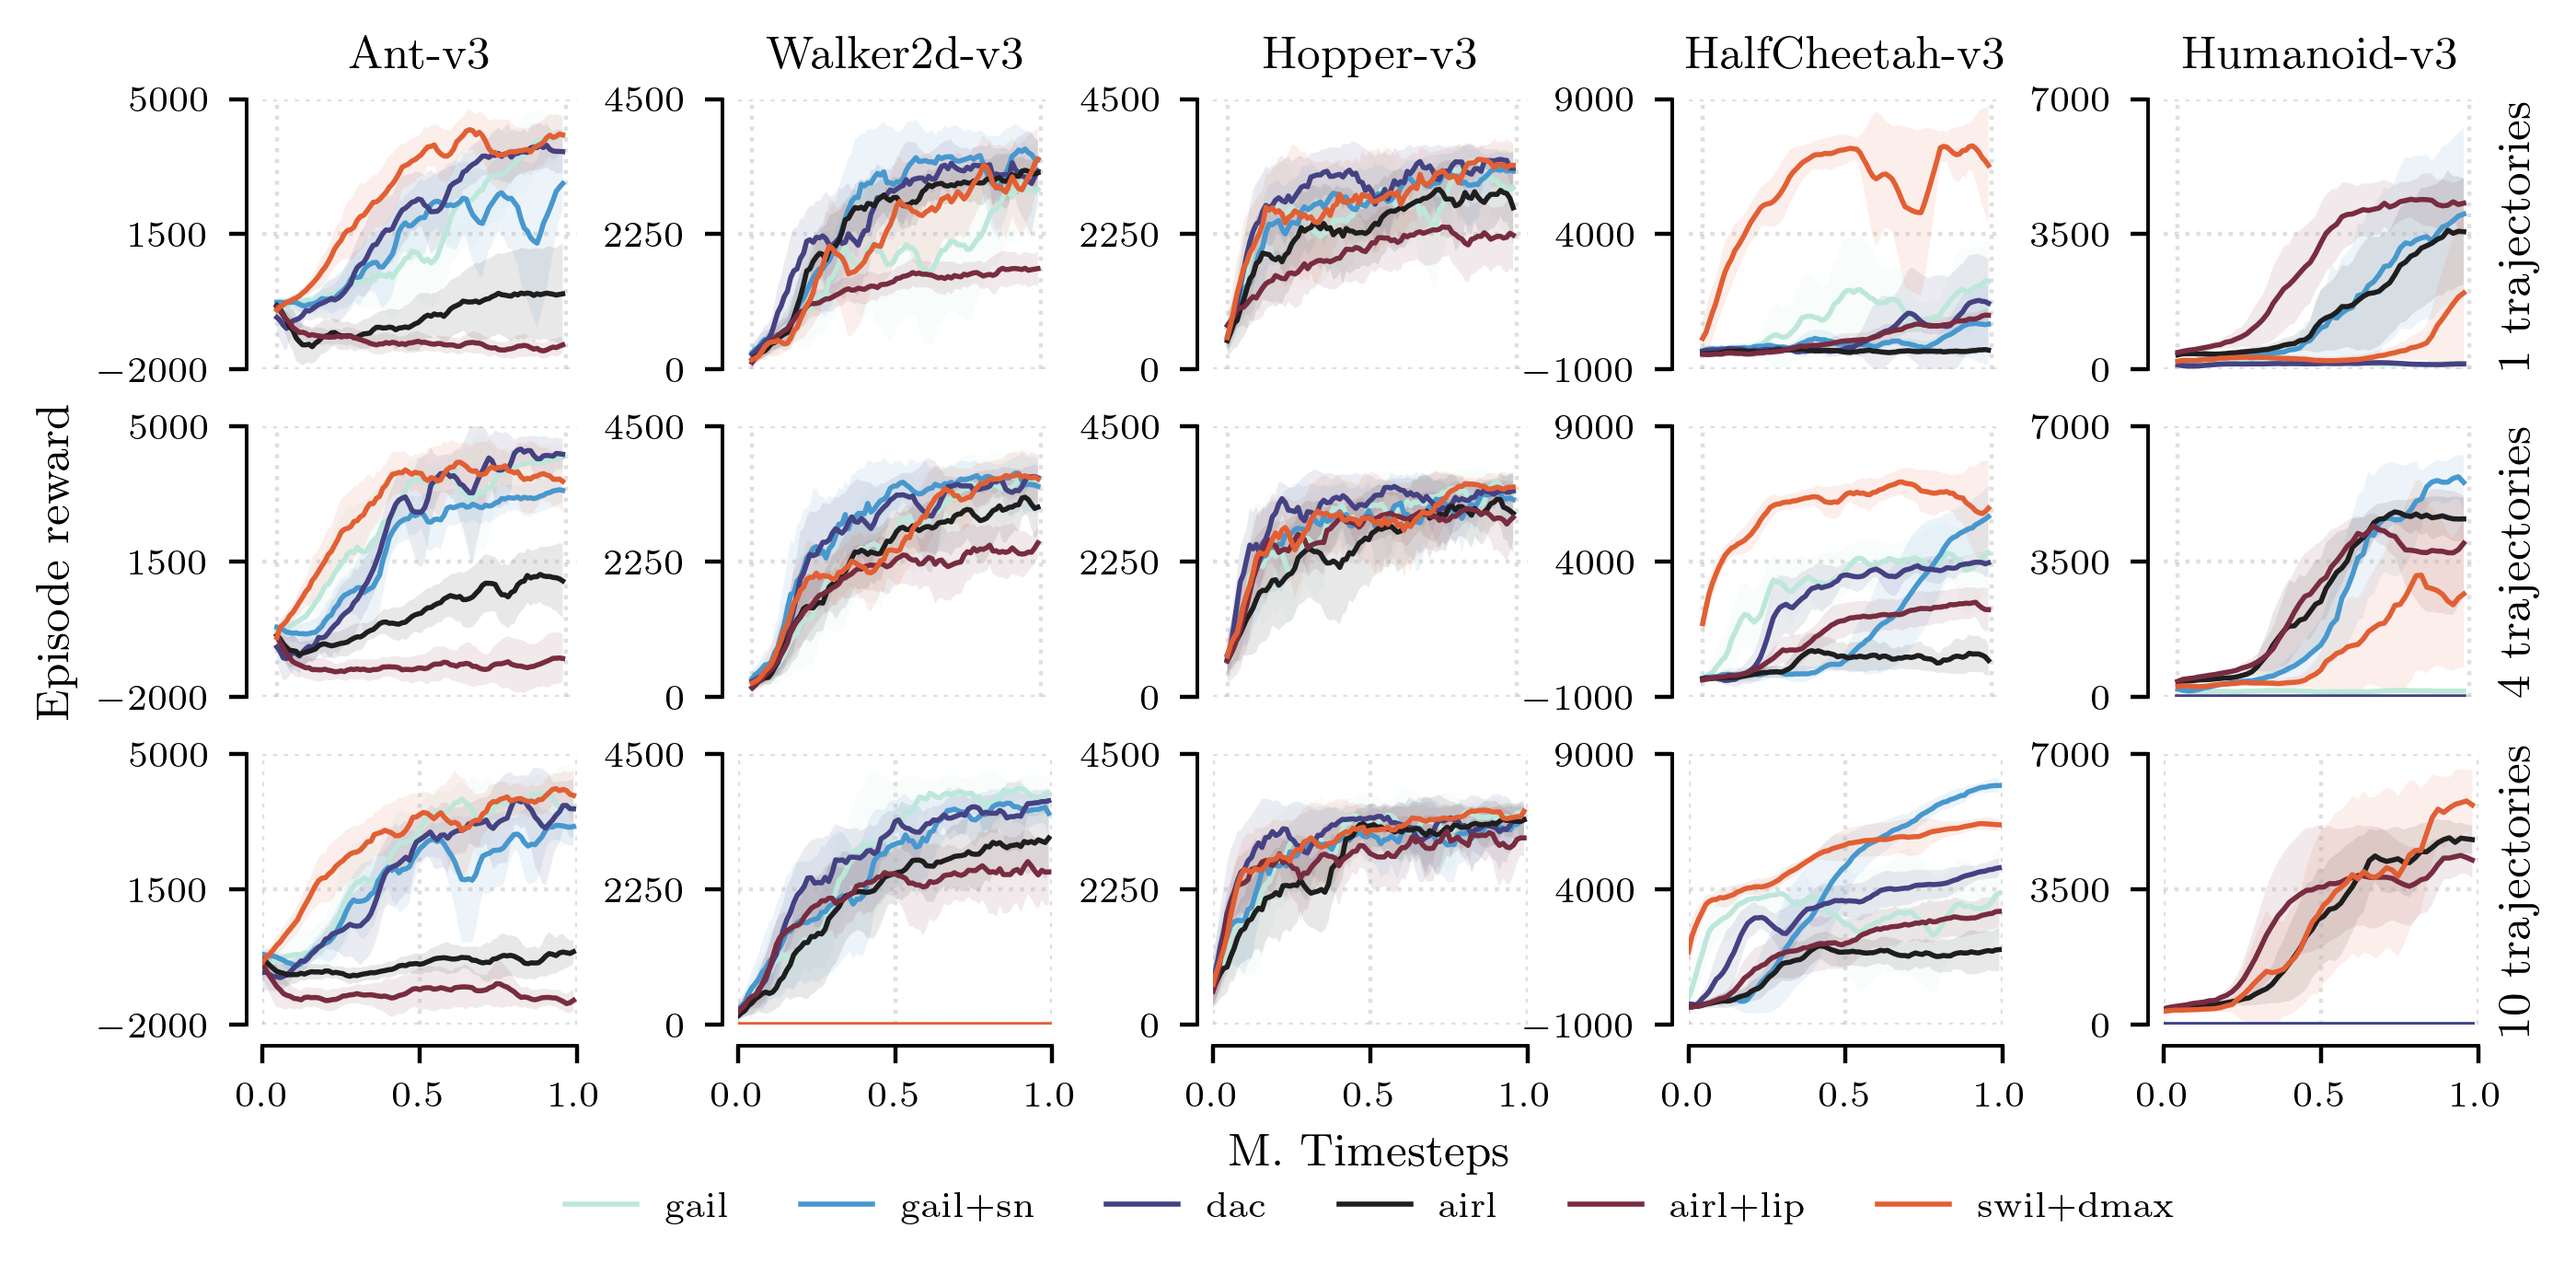

In [226]:
d_mustds = {'gail':d_gail_mustd, 
            'gail+sn':d_gail_sn_mustd, 
            'dac':d_dac_mustd, 
            'airl':d_airl_mustd, 
            'airl+lip':d_airl_lip1_mustd, 
            'swil+dmax':d_swil_2901_mustd}

def smooth_mu_std(mu, std, N=6):
    mu_s = np.convolve(mu, np.ones(N)/N, mode='valid')
    std_s = np.convolve(std, np.ones(N)/N, mode='valid')
    
    return mu_s, std_s

###
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(d_mustds.keys())
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(3,5, dpi=400, figsize=[text_width, 3])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for ss in sss:
    for i, n_d in enumerate(n_demos):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")

        for j, env in enumerate(envs):
            # plot gail
            ax[i,j].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])

            ax[0,j].set_title(env)
            #if j > 0:
                #remove_yticks(ax[i,j])
                #ax[i,j].spines[['left']].set_visible(False)
            if i < 2:
                ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                remove_xticks(ax[i,j])

            ax[i,j].spines[['top' , 'right']].set_visible(False)
            ax[i,j].spines['left'].set_position(('axes', -0.05))
            ax[i,j].spines['bottom'].set_position(('axes', -0.08))

            ax[i,j].grid(alpha=0.4, linestyle=':')
            
            # set env specific limits
            ax[i,0].set_ylim(-2000, 5000)
            ax[i,0].set_yticks([-2000, 1500, 5000])
            ax[i,1].set_ylim(0, 4500)
            ax[i,1].set_yticks([0, 2250, 4500])
            ax[i,2].set_ylim(0, 4500)
            ax[i,2].set_yticks([0, 2250, 4500])            
            ax[i,3].set_ylim(-1000, 9000)
            ax[i,3].set_yticks([-1000, 4000, 9000])                        
            ax[i,4].set_ylim(0, 7000)
            ax[i,4].set_yticks([0, 3500, 7000])                                          
            ax[2,j].set_xlim(0,1.0)
            ax[2,j].set_xticks([0, 0.5, 1.0])

            for k,v in d_mustds.items():       
                mu,std = v[env][n_d][ss]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if 'swil' in k:
                    marker = '.'
                else:
                    marker = '+'
                ax[i,j].plot(x, mu,lw=1, label=f"{k}")#, linestyle=next(linecycler)[-1])
                ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)
            
        ax[2,2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.5), fancybox=False, shadow=False, frameon=False, ncol=8)
        ax[2,2].set_xlabel('M. Timesteps')
        ax[1,0].set_ylabel('Episode reward')
        ax[0,-1].yaxis.set_label_position("right")
        ax[1,-1].yaxis.set_label_position("right")
        ax[2,-1].yaxis.set_label_position("right") 
        ax[0,-1].set_ylabel("1 trajectories")
        ax[1,-1].set_ylabel("4 trajectories")
        ax[2,-1].set_ylabel("10 trajectories")


#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"testfig1.pdf", bbox_inches='tight', pad_inches=0.01)

### Compose subsampling plot 

Incomplete length: swil Humanoid-v3 234 10 20 59


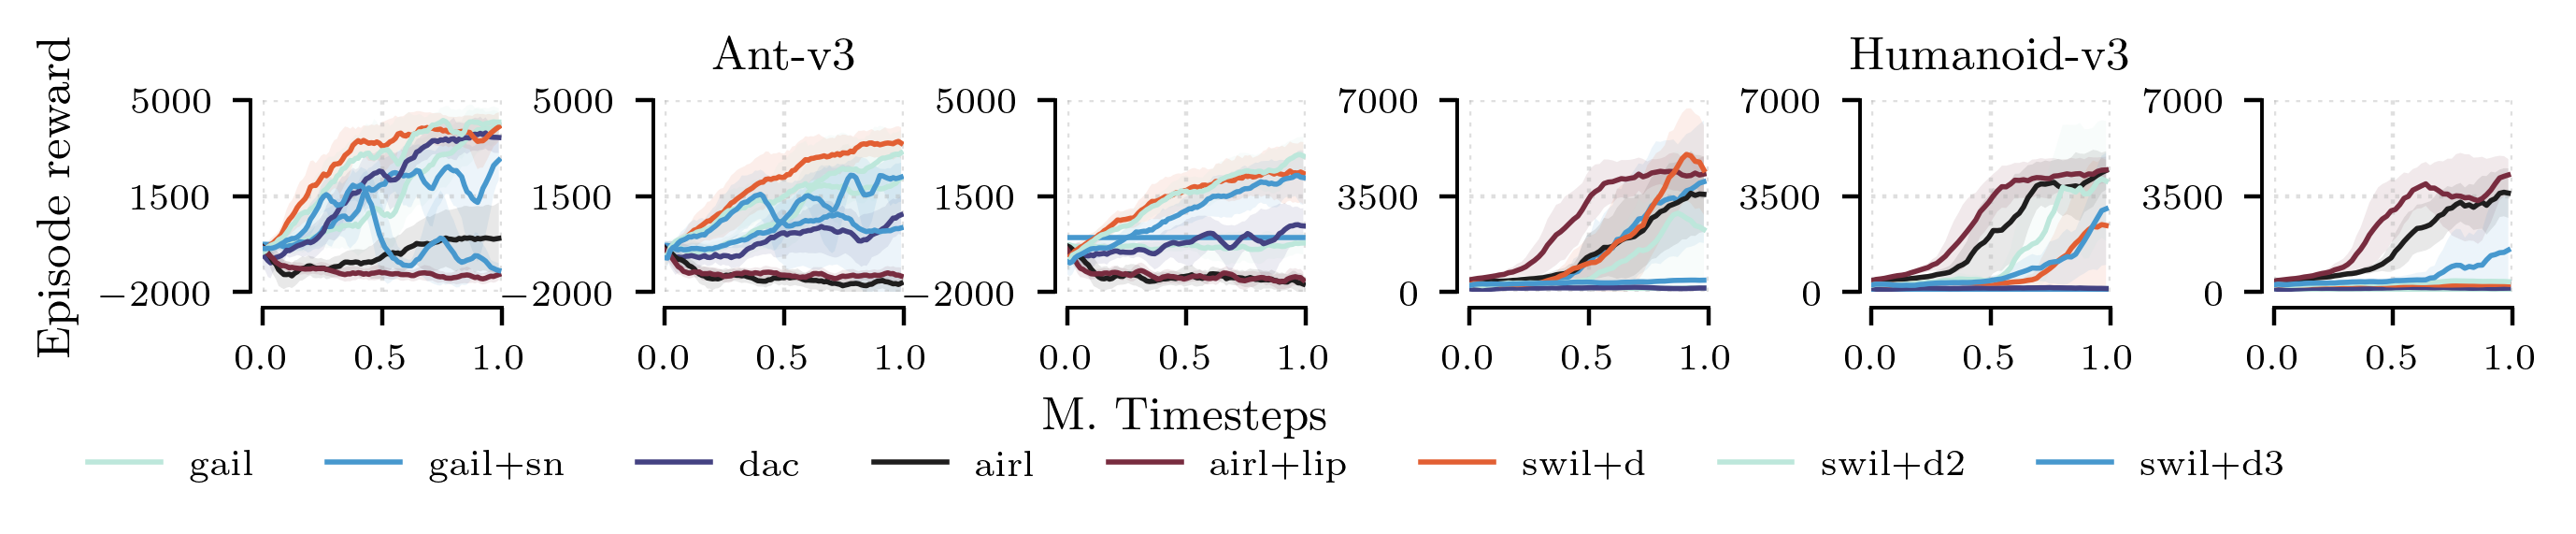

In [255]:
#d_swil, d_swil_mustd = process_results(envs, results_swil_new, ['use_next_obs', 'repl_loss_type', 'max_q_len'],['True', 'diff2max0', '1'], sss=[1])
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
d_swil_2701, d_swil_2701_mustd = process_results(envs, results_swil_2701, ['use_next_obs', 'repl_loss_type', 'max_q_len'],['True', 'diff2max0', '10'])

d_swil_old, d_swil_old_mustd = process_results(envs, results_swil_old, ['use_next_obs', 'use_dones', 'max_q_len', 'swil_period', 'replace_atoms', 'use_actions'], ['True', 'False', '10', '100.0', 'False', 'True'])
d_swil_old_2, d_swil_old_2_mustd = process_results(envs, results_swil_old, ['use_next_obs', 'use_dones', 'max_q_len', 'swil_period', 'replace_atoms', 'use_actions'], ['True', 'False', '5', '100.0', 'False', 'True'])
d_swil_old_3, d_swil_old_3_mustd = process_results(envs, results_swil_old, ['use_next_obs', 'use_dones', 'max_q_len', 'swil_period', 'replace_atoms', 'use_actions'], ['False', 'False', '10', '100.0', 'False', 'True'])

d_mustds_ss = {'gail':d_gail_mustd, 
            'gail+sn':d_gail_sn_mustd, 
            'dac':d_dac_mustd, 
            'airl':d_airl_mustd, 
            'airl+lip':d_airl_lip1_mustd, 
            #'swil+dmax':d_swil_mustd, 
            'swil+d':d_swil_old_mustd, 
            'swil+d2':d_swil_old_2_mustd,
            'swil+d3':d_swil_old_3_mustd}

def smooth_mu_std(mu, std, N=6):
    mu_s = np.convolve(mu, np.ones(N)/N, mode='valid')
    std_s = np.convolve(std, np.ones(N)/N, mode='valid')
    
    return mu_s, std_s


envs = ['Ant-v3', 'Humanoid-v3']
n_demos = [1]
sss = [1,20,100]
subsample_plot = 1
NUM_COLORS = len(d_mustds.keys())
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(1,6, dpi=400, figsize=[text_width, 1])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for n_d in n_demos:
    for j_, env in enumerate(envs):
        for i_, ss in enumerate(sss):

            #fig, ax = plt.subplots(1,5,figsize=(24,4))
            #fig.suptitle(f"ss:{ss}_nd:{n_d}")

            # re-index
            i = 1 
            j = j_*len(sss)+i_
            # plot gail
            ax[j].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])

            #if j > 0:
                #remove_yticks(ax[i,j])
                #ax[i,j].spines[['left']].set_visible(False)
            #if i < 2:
            #    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
            #    remove_xticks(ax[i,j])

            ax[j].spines[['top' , 'right']].set_visible(False)
            ax[j].spines['left'].set_position(('axes', -0.05))
            ax[j].spines['bottom'].set_position(('axes', -0.08))

            ax[j].grid(alpha=0.4, linestyle=':')
            
            # set env specific limits

            ax[j].set_ylim(0, 7000)
            ax[j].set_yticks([0, 3500, 7000])                                          
            ax[j].set_xlim(0,1.0)
            ax[j].set_xticks([0, 0.5, 1.0])
            ax[i_].set_ylim(-2000, 5000)
            ax[i_].set_yticks([-2000, 1500, 5000])
                      
            for k,v in d_mustds_ss.items(): 
                mu,std = v[env][n_d][ss]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]
                
                x = np.arange(len(mu))/len(mu)
                if 'swil' in k:
                    marker = '.'
                else:
                    marker = '+'
                ax[j].plot(x, mu,lw=1, label=f"{k}")#, linestyle=next(linecycler)[-1])
                ax[j].fill_between(x,mu+std, mu-std, alpha=0.1)
            
            
        ax[1].set_title('Ant-v3')
        ax[4].set_title('Humanoid-v3')

        ax[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.65), fancybox=False, shadow=False, frameon=False, ncol=8)
        ax[2].set_xlabel('M. Timesteps')
        ax[0].set_ylabel('Episode reward')


#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"testfig2.pdf", bbox_inches='tight', pad_inches=0.01)

### Compose plot for Adroit Franka figure (Appendix)

In [139]:
envs = ['AdroitHandDoor-v1', 'AdroitHandPen-v1', 'FrankaKitchen-v1']
results_swil_adrfra = pkl.load(open('260124_swil_adrfra_results.pkl','rb'))
results_gail_adrfra = pkl.load(open('211124_gail_adrfra_results.pkl','rb'))
results_pwil_adrfra = pkl.load(open('260124_pwil_adrfra_results.pkl','rb'))
results_airl_adrfra = pkl.load(open('260124_airl_adrfra_results.pkl','rb'))

# NOTE swil_period is float!
d_swil_adrfra, d_swil_adrfra_mustd = process_results(envs, results_swil_adrfra, ['subsample', 'n_demos', 'atom_weight', 'swil_period', 'use_next_obs', 'shuffle_irl_batches', 'repl_loss_type', 'max_q_len', 'drop_batch'],
                                                                                ['1','10', '1/n', '100.0', 'False', 'True', 'diff2max0', '1', 'True'], sss=[1], n_demos=[10], print_files=False)
d_gail_adrfra, d_gail_adrfra_mustd  = process_results(envs, results_gail_adrfra, ['use_actions', 'n_demos', 'use_spectral_norm'], ['True', '10', 'True'], sss=[1], n_demos=[10])
#d_pwil_adrfra, d_pwil_adrfra_mustd  = process_results(envs, results_pwil_adrfra, ['use_actions', 'n_demos'], ['True', '10'], sss=[1], n_demos=[10])
d_airl_adrfra, d_airl_adrfra_mustd  = process_results(envs, results_airl_adrfra, ['subsample', 'n_demos', 'use_actions', 'lip_coeff'], ['1', '10', 'True', '0'], sss=[1], n_demos=[10])

d_mustds_adrfra = {'gail':d_gail_adrfra_mustd, 'airl': d_airl_adrfra_mustd, 'swil': d_swil_adrfra_mustd}

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


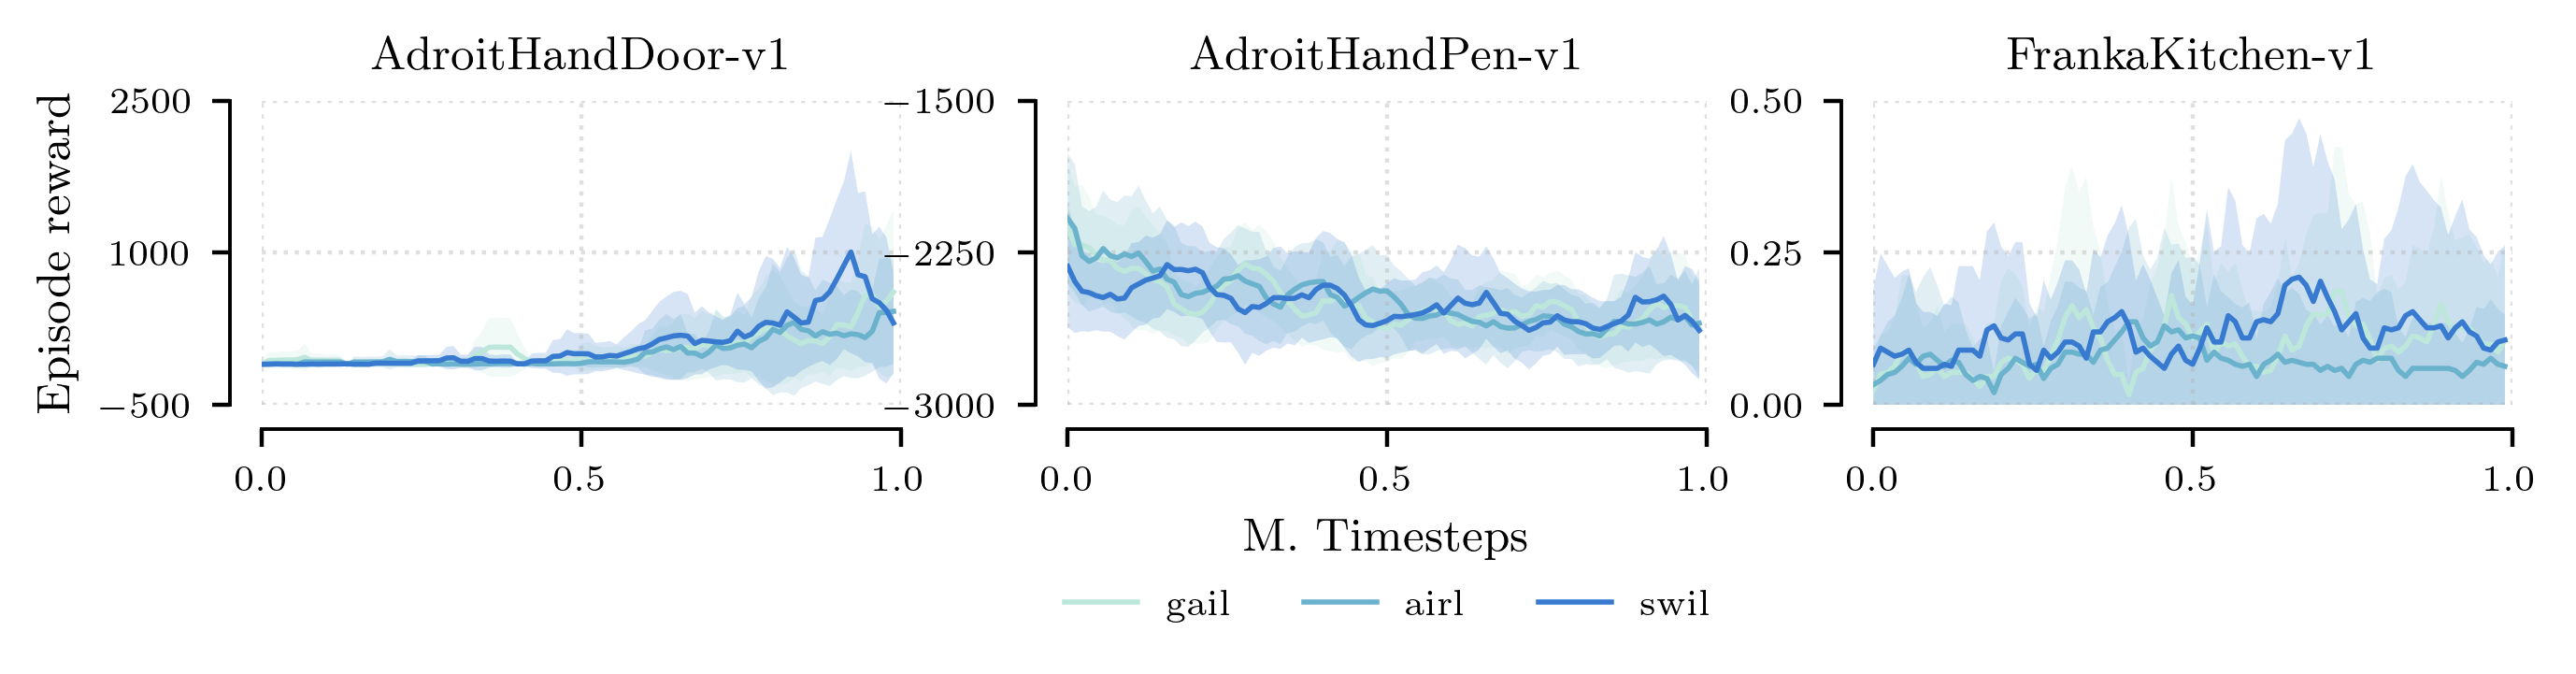

In [216]:
envs = ['AdroitHandDoor-v1', 'AdroitHandPen-v1', 'FrankaKitchen-v1']
n_demos = [10]
sss = [1]
text_width = 6.6
text_height = 9.0
subsample_plot = 1
fig,ax = plt.subplots(1,3, dpi=400, figsize=[text_width, 1.3])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout()

for n_d in n_demos:
    for j_, env in enumerate(envs):
        for i_, ss in enumerate(sss):

            #fig, ax = plt.subplots(1,5,figsize=(24,4))
            #fig.suptitle(f"ss:{ss}_nd:{n_d}")

            # re-index
            i = 1 
            j = j_*len(sss)+i_
            
            
            ax[j].set_prop_cycle('color', [cm(1.*i/NUM_COLORS) for i in range(NUM_COLORS)])
            
            ax[j].set_title(env)

            #ax[1].set_title('Ant-v3')
            #ax[4].set_title('Humanoid-v3')

            #if i_ > 0:
            #    remove_yticks(ax[j])
            #    ax[j].spines[['left']].set_visible(False)
            #if i < 2:
            #    ax[j].spines[['top', 'bottom', 'right']].set_visible(False)
            #    remove_xticks(ax[j])

            ax[j].spines[['top' , 'right']].set_visible(False)
            ax[j].spines['left'].set_position(('axes', -0.05))
            ax[j].spines['bottom'].set_position(('axes', -0.08))

            ax[j].grid(alpha=0.4, linestyle=':')
            
                                   
            
            ax[j].set_xlim(0,1.0)
            ax[j].set_xticks([0, 0.5, 1.0])

            for k,v in d_mustds_adrfra.items():       
                mu,std = v[env][n_d][ss]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if 'swil' in k:
                    marker = '.'
                else:
                    marker = '+'
                ax[j].plot(x, mu,lw=1, label=f"{k}")#, linestyle=next(linecycler)[-1])
                ax[j].fill_between(x,mu+std, mu-std, alpha=0.2)
           
        
            # set specific 
            #ax[i_].set_ylim(-2000, 4000)
            #ax[i_].set_yticks([-2000, 1500, 5000])                  
            #ax[j].set_ylim(0, 7000)
            #ax[j].set_yticks([0, 3500, 7000])       
        ax[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.5), fancybox=False, shadow=False, frameon=False, ncol=8)
        ax[1].set_xlabel('M. Timesteps')
        ax[0].set_ylabel('Episode reward')
        
        ax[0].set_ylim(-500, 2500)
        ax[0].set_yticks([-500, 1000, 2500])                                          
        ax[1].set_ylim(-3000, -1500)
        ax[1].set_yticks([-3000, -2250, -1500])     
        ax[2].set_ylim(0.0, 0.5)
        ax[2].set_yticks([0, 0.25, 0.5])                                          
        #ax[i_].set_ylim(-2000, 5000)
        #ax[i_].set_yticks([-2000, 1500, 5000])


### Compose plot for Adroit, Franka

## 

In [ ]:
font_size = 32
matplotlib.rcParams['font.size'] = font_size
matplotlib.rcParams["font.weight"] = "bold"
matplotlib.rcParams['text.usetex'] = False
matplotlib.rcParams['axes.labelsize'] = font_size
matplotlib.rcParams['axes.titlesize'] = font_size
matplotlib.rcParams['legend.fontsize'] = 28
matplotlib.rcParams['xtick.labelsize'] = font_size
matplotlib.rcParams['ytick.labelsize'] = font_size
sns.set_style(style='white')
#matplotlib.rcParams['text.latex.preamble']=r'\usepackage{amsmath} \DeclareMathOperator{\F}{F} \DeclareMathOperator{\GMF}{GMF} \DeclareMathOperator{\MLP}{MLP}'

### Ablation study 2 (histogram plot)
for Humanoid and Ant across all n_demos
Variations: measurable space (get sxs results)? queue length? Replace atoms

In [ ]:
tags = ["charts/episodic_return", "irl/gail_bce_loss", "eval/mu"]

#nonlin="leakyrelu"
#lin = '--linear_proj'
#nob = ''

algos = ['sac']
disc_types = ['swil']
lins = ['', '--replace_atoms']
usenobs = ['', '--use_actions', '--use_next_obs--use_actions', '--use_next_obs--use_actions--use_dones']

qlens = [1,5,10]
subsamplings = [1,20,100]
periods = [100]
disc_nonlins = ['tanh']
print(lins)

for algo in X:
    for ss in subsamplings:
        for nob in usenobs:
            for per in periods:
                for ql in qlens:
                    for nonlin in disc_nonlins:
                        fig, axs = plt.subplots(1,5, figsize=(24,4))
                        fig.subplots_adjust(top=0.88)
                        fig.suptitle(f"{algo}_subsmpl:{ss}_{nob}_nonlin:{nonlin}_period:{per}_qlen:{ql}")
                        plt.style.use('ggplot')
                        #print(lin, nob, nonlin)
                        #plt.title(lin + nob + nonlin)
                        for i, env in enumerate(envs):

                            X_axis = np.arange(len(lins))

                            axs[i].set_title(env)
                            X_index = []
                            Y_mean = []
                            Y_std = []
                            ndem = [1,4,10]

                            for j,n_d in enumerate(ndem):
                                Y = []
                                Y_ = []

                                for k,lin in enumerate(lins):
                                    val_list = []
                                    for seed in [515, 234, 894, 322, 72]:
                                        ea = d_swil[env][seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['swil'][f"per_{per}"][f"ql_{ql}"]
                                        if not isinstance(ea,dict):
                                            df = create_df_from_ea(ea, tags[-1])
                                            val_list.append(np.max(df['Value']))

                                    if len(val_list) > 0:
                                        Y.append(np.mean(val_list))
                                        Y_.append(np.std(val_list))
                                    else:
                                        Y.append(0)            
                                        Y_.append(0)

                                #print(f"{env_name}[seed][f"ss_{ss}"][f"nd_{n_d}"][lin][nob][nonlin]['swil'][f"per_{per}"][f"ql_{ql}"Y, Y_)

                                axs[i].bar(X_axis-0.2+j*0.2, Y, 0.2, label=f"{n_d} traj") 
                                axs[i].errorbar(X_axis-0.2+j*0.2, Y, yerr=Y_, fmt=".", color='k') 


                        axs[0].set_ylabel("Cumulative reward")
                        axs[-1].legend(loc='center left', bbox_to_anchor=(1, 0.5))

                        #plt.legend()
                        plt.tight_layout()

## Table 1

In [ ]:
for ss in subsamplings:
    for n_demo in n_demos:
        for lin in lins:
            for ua in usenobs:
                for per in periods:
                    for qlen in qlens:
                        env = 'HalfCheetah-v3'
                        #print(env, f"ss_{ss}", f"nd_{n_demo}", lin, ua, f"per_{per}", f"ql_{qlen}")
                        #print(np.mean(d_mustd_swil[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_{per}"][f"ql_{qlen}"][0][-5:]))

lins = ['', '--irm_coeff=1.0', '--use_spectral_norm', '--lip_coeff=10.0--use_absorb_wrapper']
usenobs = ['', '--use_actions']

subsamplings = [1,20,100]
n_demos = [1]

for ss in subsamplings:
    for n_demo in n_demos:
        for lin in lins:
            for ua in usenobs:
                env = 'Ant-v3'
                print(env, f"ss_{ss}", f"nd_{n_demo}", lin, ua)
                print("mean", np.mean(d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][0][-5:]))
                print(np.mean(d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][1][-5:]))
                print("max", np.max(d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][0]))
                print(np.max(d_mustd_airl[env][f"ss_{ss}"][f"nd_{n_demo}"][lin][ua][f"per_-1"][f"ql_1"][1]))